# 08 — The museum guide (A10)

The demo of the project: a visitor takes a photo of a painting, and the guide tells them the style, how sure it is, and a short story about the movement. If the model isn't sure enough, the guide says so instead of making something up.

1. The texts the guide shows (`museum/stories.md`).
2. Choosing the "not sure" threshold on the validation set.
3. Which model the guide uses.
4. A few demo cards for the slides.

The guide works with any of our saved candidates (`checkpoints/`, written by notebooks 03, 05 and 06). Only the validation set is used here.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")
from museum.data import CLASSES, ROOT, get_arrays
from museum.guide import (
    CHECKPOINTS,
    GUIDE,
    MuseumGuide,
    choose_threshold,
    coverage_table,
    load_predictor,
    render_card,
)
from museum.stories import NOT_SURE, WORD_LIMITS, load_stories

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: the checkpoints come from quick runs
FIG_DIR = ROOT / "results" / "figures"
X_val, y_val = get_arrays(128, "val")
CANDIDATES = [name for name in ["ffn", "resnet_frozen", "resnet_finetune"] if (CHECKPOINTS / f"{name}.pt").exists()]
assert CANDIDATES, "run notebooks 03, 05 and 06 first: they write the checkpoints"
print("saved candidates:", CANDIDATES)

saved candidates: ['ffn', 'resnet_frozen', 'resnet_finetune']


## 1. The texts

One section per style, plus the message for when the guide isn't sure. The word limits keep the texts readable on a phone (`tests/test_stories.py` checks them).

In [2]:
stories = load_stories()
sections = [*CLASSES, NOT_SURE]
counts = pd.DataFrame([{field: len(text.split()) for field, text in stories[name].items()} for name in sections],
                      index=sections).astype("Int64")
print("word limits:", WORD_LIMITS)
counts.map(lambda n: "" if pd.isna(n) else str(int(n)))

word limits: {'Story': 120, 'What to look for': 60, 'Message': 40}


,Period,Story,What to look for,Famous example,Message
Baroque,17,90,38,7,
Cubism,7,101,46,17,
Impressionism,5,99,50,9,
Pop_Art,10,106,35,9,
Ukiyo_e,8,99,36,9,
Not sure,,,,,31


## 2. The "not sure" threshold

The guide only names a style when the model's confidence (its highest softmax probability) is above a threshold. Below it, it shows the "not sure" message.

- **The rule, fixed before looking at the numbers:** when the guide names a style, it should be right at least 90 % of the time. A wrong story in front of a painting is worse than "not sure", so we take the lowest threshold that reaches 90 % on the validation images it answers. The lowest one, because then it answers as many visitors as possible.
- **Where exactly the cut-off goes:** halfway between the last image answered and the next one down. Then tiny float differences (one photo at a time instead of a batch, another machine) can't push an image to the other side.
- **Coverage** is the share of images the guide answers.

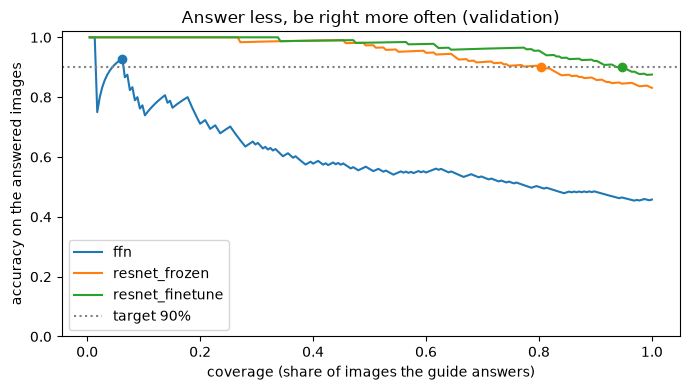

,val acc (answers everything),threshold,coverage,accuracy when it answers
model,,,,
ffn,0.458,0.819,0.062,0.929
resnet_frozen,0.831,0.545,0.804,0.901
resnet_finetune,0.876,0.544,0.947,0.901


In [3]:
TARGET = GUIDE["target_accuracy"]
rows, curves, probs = [], {}, {}
for name in CANDIDATES:
    probs[name] = load_predictor(name).predict_proba(X_val)
    table = coverage_table(probs[name], y_val)
    curves[name] = table
    threshold = choose_threshold(probs[name], y_val, TARGET)
    answered = probs[name].max(axis=1) >= threshold
    right = probs[name].argmax(axis=1) == y_val
    rows.append({"model": name, "val acc (answers everything)": right.mean(), "threshold": threshold,
                 "coverage": answered.mean(), "accuracy when it answers": right[answered].mean()})
thresholds = pd.DataFrame(rows).set_index("model")

fig, ax = plt.subplots(figsize=(7, 4))
for name, table in curves.items():
    ax.plot(table["coverage"], table["accuracy"], label=name)
    point = thresholds.loc[name]
    ax.scatter(point["coverage"], point["accuracy when it answers"], zorder=3)
ax.axhline(TARGET, color="grey", ls=":", label=f"target {TARGET:.0%}")
ax.set(xlabel="coverage (share of images the guide answers)", ylabel="accuracy on the answered images",
       ylim=(0, 1.02), title="Answer less, be right more often (validation)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "guide_threshold.png", dpi=150, bbox_inches="tight")
plt.show()
thresholds.round(3)

**What we see.**
- **The fine-tuned ResNet only has to stay quiet on 5 % of the images.** It answers 95 % of them (213 of 225) and is right 90.1 % of those times.
- **The frozen ResNet** has to stay quiet on 20 % of them (coverage 80 %) for the same 90 %.
- **The FFN** can only answer 6 % of the images (14 out of 225). When it answers everything, it's right 46 % of the time.

So the threshold trick works for a decent model, but it can't save a weak one. The better the model, the fewer visitors hear "not sure".

## 3. The guide's model

The final test run (`07_comparison`) found that no candidate meets all three criteria. **The fine-tuned ResNet18 comes closest:** 84.0 % on the test set (3 images short of 85 %), and it passes latency and footprint. It's also the best of our saved candidates on validation, so it's the guide's model.

**About its weights.** The checkpoint used in the final run was overwritten afterwards, so the file used here was retrained on this laptop with the same frozen recipe and seed (`06_resnet_finetune`). In a reproduction of the final run it scored 84.4 % on the test set, one image away from the official 84.0 %.

The chosen model and the thresholds are written in `museum/guide.py` (`GUIDE`), so the command line uses the same ones. The cell compares them with this run.

In [4]:
best = thresholds["val acc (answers everything)"].idxmax()
chosen = {name: float(thresholds.loc[name, "threshold"]) for name in thresholds.index}
print(f"guide model: {best} | thresholds: {chosen}")
if FAST_RUN:
    print("FAST_RUN: the checkpoints come from quick runs, so GUIDE in museum/guide.py isn't compared")
elif GUIDE["model"] == best and all(abs(GUIDE["thresholds"].get(name, -1) - t) < 1e-9 for name, t in chosen.items()):
    print("GUIDE in museum/guide.py matches this run")
else:
    print(f"warning: GUIDE in museum/guide.py ({GUIDE['model']}, {GUIDE['thresholds']}) differs from this run")

guide = MuseumGuide(load_predictor(best), chosen[best])   # one image at a time, like the real guide
answers = [guide.ask(image) for image in X_val]
named = np.array([a.label is not None for a in answers])
right = np.array([a.label == CLASSES[y] for a, y in zip(answers, y_val, strict=True)])
print(f"on the 225 validation images the guide names a style {named.mean():.0%} of the time "
      f"and is right {right[named].mean():.1%} of those times")

guide model: resnet_finetune | thresholds: {'ffn': 0.8186502456665039, 'resnet_frozen': 0.5449391603469849, 'resnet_finetune': 0.5437513589859009}
GUIDE in museum/guide.py matches this run


on the 225 validation images the guide names a style 95% of the time and is right 90.1% of those times


**What we see.** With the fine-tuned ResNet and a threshold of 0.544, the guide names a style for 95 % of the validation images and gets 90.1 % of those right. The other 5 % get the "not sure" message.

**Keep in mind:** the 90 % is a bit optimistic, because the threshold was chosen on these same validation images. On the test set, the model is right 84 % of the time when it answers everything (`07_comparison`). The threshold removes its least sure answers, which are the ones most often wrong, so the guide should do better than that. We didn't measure it on the test set, to keep the test set for the one final comparison.

## 4. Demo cards

Three validation images: the guide's most confident answer, an answer close to the threshold, and the image it is least sure about.

card 1 (most confident): true style Ukiyo_e, guide says Ukiyo-e (100%)


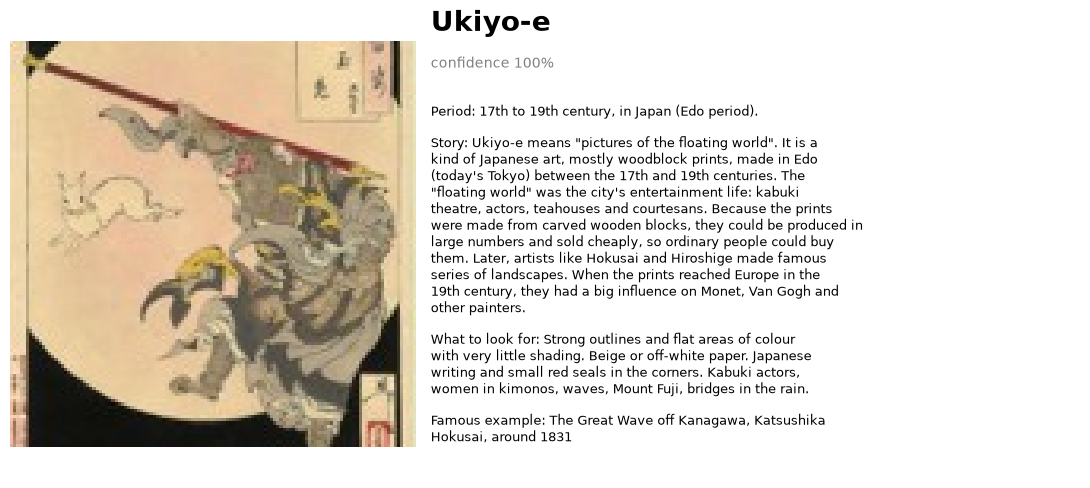

card 2 (close to the threshold): true style Impressionism, guide says Impressionism (54%)


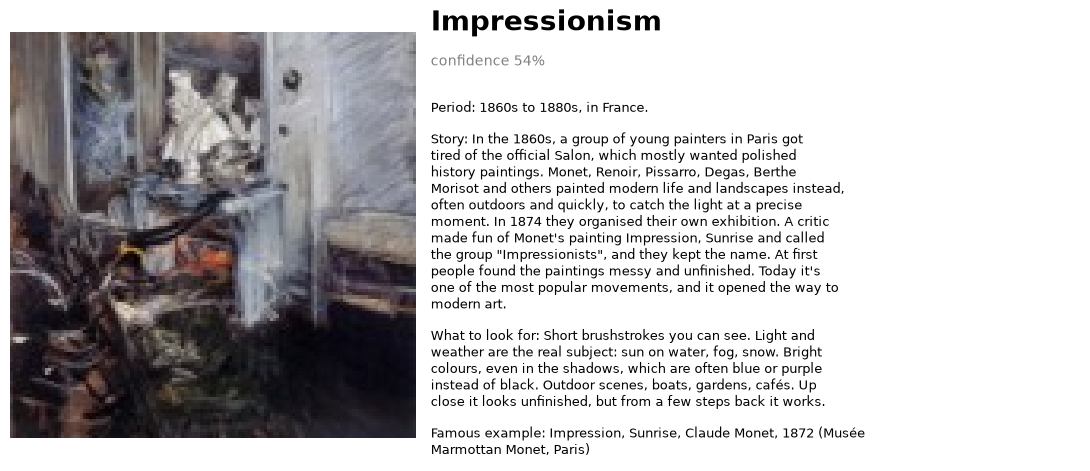

card 3 (least sure): true style Baroque, guide says not sure (35%)


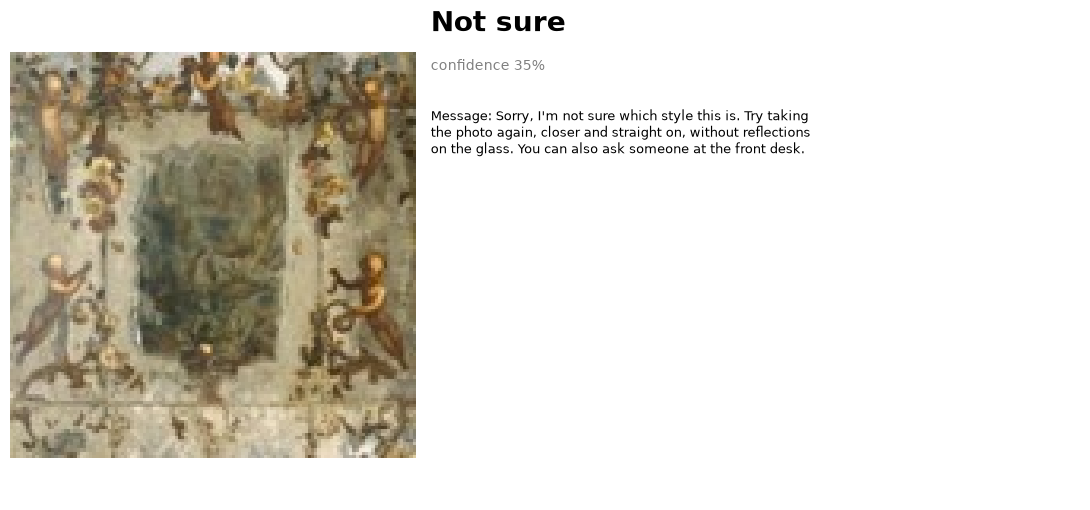

In [5]:
confidence = np.array([a.confidence for a in answers])
named_idx = np.flatnonzero(named)
examples = {
    "most confident": int(named_idx[np.argmax(confidence[named_idx])]),
    "close to the threshold": int(named_idx[np.argmin(confidence[named_idx])]),
    "least sure": int(np.argmin(confidence)),
}
for i, (label, index) in enumerate(examples.items(), start=1):
    answer = answers[index]
    print(f"card {i} ({label}): true style {CLASSES[y_val[index]]}, guide says {answer.style or 'not sure'} "
          f"({answer.confidence:.0%})")
    fig = render_card(X_val[index], answer, path=FIG_DIR / f"guide_card_{i}.png")
    plt.show()

**What we see.**
- **Card 1:** a Ukiyo-e print the guide is 100 % sure about. Basically the textbook case.
- **Card 2:** an Impressionist interior just above the threshold (54 %). The guide answers, and it's right.
- **Card 3:** a Baroque ceiling decoration, cherubs and garlands around a dark panel. It doesn't look like a typical Baroque painting; the guide is only 35 % sure, and it says so instead of guessing.

The cards are saved as `results/figures/guide_card_*.png` for the demo slide.

## Summary

- **How the guide decides.** It names a style only when the model is confident enough, and otherwise says it isn't sure. The threshold is chosen on validation so that it's right at least 90 % of the time when it answers.
- **Its model.** The guide uses the fine-tuned ResNet18, the closest candidate in the final comparison. It answers 95 % of visitors and is right 90 % of the time (validation).
- **The other models.** The frozen ResNet would answer 80 % of visitors, the FFN only 6 %.
- **To try it on a photo:** `PYTHONPATH=src python -m museum.guide path/to/photo.jpg`. The photo is turned upright and cropped to a square in the middle, like the dataset images.
- **Its weights** were retrained here with the frozen recipe, since the final-run checkpoint was overwritten. In our reproduction of the final run it scored 84.4 % on the test set, against the official 84.0 %.